# Task 1 — N-gram language models on the GPAC Amharic corpus

This notebook builds n-gram counts for n = 1..4 over the General-Purpose Amharic Corpus (GPAC)
and answers questions 1.1–1.8. The heavy lifting lives in the `ngram` package of this repository:

| module | role |
|---|---|
| `ngram.normalize` | homophone normalization, sentence splitting, tokenization |
| `ngram.corpus` | train/dev/test split and corpus statistics |
| `ngram.counts` | n-gram tables stored as sorted integer arrays |
| `ngram.models` | MLE, Laplace and interpolated Kneser-Ney models |
| `ngram.generate` | random sentence generation and next-word suggestion |

In [1]:
# --- Setup ---------------------------------------------------------------------------
# On Colab / Kaggle, first get this repository and the corpus:
#   !git clone <your-repo-url> nlp-assignment-1
#   %cd nlp-assignment-1
#   !pip install -q wordcloud gdown
#   !gdown 1jEOAORylTBAiNKes_JerD6gFF7cnLFyr -O data/   # GPAC, from the assignment's Drive link
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")
CORPUS = os.path.join(DATA, "GPAC.txt")     # a .txt file, a directory of .txt files, or a .zip
MODEL_DIR = os.path.join(DATA, "gpac")      # preprocessed splits, vocabulary and counts go here
FIGURES = os.path.join(ROOT, "figures"); os.makedirs(FIGURES, exist_ok=True)
MAX_CHARS = None                            # e.g. 50_000_000 to use only part of the corpus

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)

## 1.1 Preprocessing and corpus statistics

Preprocessing steps, in order:

1. **Homophone normalization.** Amharic has letter series that are pronounced the same and are
   used interchangeably in writing: ሐ and ኀ are pronounced like ሀ, ሠ like ሰ, ዐ like አ, ፀ like ጸ,
   and the a-order letters ሃ, ኃ, ሓ, ኣ, ዓ like the first-order ሀ and አ. Each such variant of a word
   would otherwise be a separate vocabulary entry with its own sparse counts, so every series is
   mapped to one canonical series (ሐገር → ሀገር, ዓለም → አለም).
2. **Sentence splitting** on ። ፧ ? ! and `::` (the ASCII stand-in for ።).
3. **Tokenization.** ፡ (the traditional word separator) becomes a space; other punctuation
   (፣ ፤ ፥ ፦ « » quotes, brackets, …) is removed; digit runs become `<num>` (so 2015 → `<num>`,
   3ኛ → `<num>ኛ`); tokens without Ethiopic letters (Latin words, URLs) are dropped.
   GPAC was distributed with every `.` replaced by a space, which splits decimals and
   abbreviations. Two repairs undo this: a bare `<num>` right after a number token is dropped
   (8.4 was written `8 4`), and known abbreviations are rejoined (`ዓ ም` → ዓም for ዓ.ም,
   `እ ኤ አ` → እኤአ for እ.ኤ.አ, plus km, kg, ወ.ዘ.ተ, ዶ/ር, …; see `ABBREVIATIONS` in
   `ngram/normalize.py`).
4. **Split** 90 / 5 / 5 into train / dev / test by sentence, with a fixed random seed.
5. **Vocabulary.** Training words seen at least twice. Every other word maps to `<unk>`, so held-out
   text never contains a word the model has no probability for.
6. **Boundaries.** Each sentence is wrapped as `<s> w1 … wm </s>`. n-grams never span two sentences.
7. **Pruning.** All unigrams and bigrams are kept. 3- and 4-grams seen only once are dropped after
   counting, because the full tables would not fit in this machine's memory. Totals, distinct
   counts and counts-of-counts are recorded before pruning, so the statistics below are exact.

In [2]:
from ngram import pipeline
vocab, counts, ids, stats = pipeline.build(CORPUS, MODEL_DIR, order=4, max_chars=MAX_CHARS)

done


In [3]:
keys = ["sentences", "tokens", "characters", "avg_sentence_length", "dropped_tokens",
        "raw_types", "normalized_types", "raw_hapax", "normalized_hapax",
        "normalized_type_token_ratio", "normalized_avg_word_length"]
summary = pd.Series({k: stats[k] for k in keys}, name="value").to_frame()
summary.loc["vocabulary (count >= 2, incl. <s> </s> <unk>)"] = len(vocab)
summary.loc["types removed by normalization"] = stats["raw_types"] - stats["normalized_types"]
display(summary)
display(pd.DataFrame({"sentences": stats["split_sentences"], "tokens": stats["split_tokens"]}))

,value
sentences,5.088850e+06
tokens,7.661745e+07
characters,4.243977e+08
avg_sentence_length,1.505595e+01
dropped_tokens,2.000000e+00
raw_types,1.974449e+06
normalized_types,1.886701e+06
raw_hapax,8.458560e+05
normalized_hapax,8.075570e+05
normalized_type_token_ratio,2.462495e-02


,sentences,tokens
train,4580232,68962429
dev,254675,3836148
test,253943,3818870


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
word,ነው,<num>,ላይ,ውስጥ,ወደ,እና,ጋር,ነበር,ግን,ጊዜ,ነገር,ደግሞ,አንድ,ይህ,ብቻ,አቶ,እንደ,መንግስት,ቤት,ስራ
count,1164092,788326,754453,346455,330697,318475,291478,274607,271301,243924,217453,209272,193015,178953,170311,168935,168011,167116,165681,158067


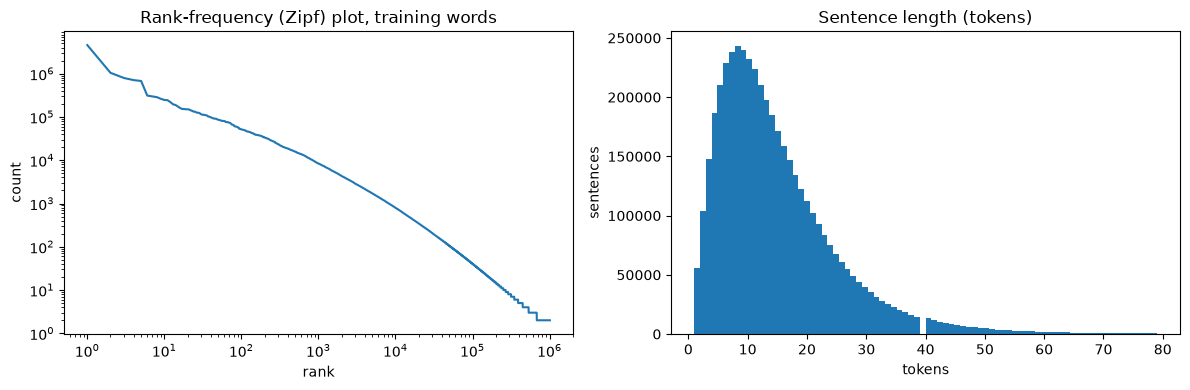

In [4]:
from ngram.vocab import BOS
uni = counts.counts[0].copy()
uni[counts.keys[0] == BOS] = 0
freq = np.sort(uni[uni > 0])[::-1]
train = ids["train"]
sent_len = np.diff(np.flatnonzero(train == BOS)) - 2      # minus <s> and </s>

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(np.arange(1, len(freq) + 1), freq)
ax[0].set(title="Rank-frequency (Zipf) plot, training words", xlabel="rank", ylabel="count")
ax[1].hist(sent_len[sent_len < 80], bins=80)
ax[1].set(title="Sentence length (tokens)", xlabel="tokens", ylabel="sentences")
plt.tight_layout(); plt.savefig(f"{FIGURES}/corpus_stats.png", dpi=150)
pd.DataFrame(stats["top_words"][:20], columns=["word", "count"]).T

## 1.2 n-grams for n = 1, 2, 3, 4

Each order k is stored as a sorted table of distinct k-grams with their counts (see `ngram/counts.py`).
Below: the number of distinct n-grams per order, every n-gram of one training sentence, and random
samples from each table.

In [5]:
def gram_str(k, rows):
    return [" ".join(vocab.decode(g)) for g in counts.decode(k, rows)]

pd.DataFrame({"n": range(1, 5),
              "n-gram occurrences": counts.meta["total"],
              "distinct n-grams": counts.meta["distinct"],
              "seen once": counts.meta["n1"],
              "kept (count >= min count)": [counts.num_grams(k) for k in range(1, 5)]})

,n,n-gram occurrences,distinct n-grams,seen once,kept (count >= min count)
0,1,78122893,1008337,0,1008337
1,2,73542661,21116487,12121142,21116487
2,3,68962429,40747675,28113351,12634324
3,4,64382197,46237996,34044279,12193717


In [6]:
with open(f"{MODEL_DIR}/train.txt", encoding="utf-8") as f:
    example = next(l.split() for l in f if 6 <= len(l.split()) <= 10)
padded = ["<s>"] + example + ["</s>"]
for n in range(1, 5):
    print(f"{n}-grams:", [" ".join(padded[i:i + n]) for i in range(len(padded) - n + 1)])

1-grams: ['<s>', '<num>ኛው', 'ቢግ', 'ብራዘርስ', 'አፍሪካ', 'አብሮ', 'የመኖር', 'ውድድር', 'በደቡብ', 'አፍሪካ', 'ተካሂዷል', '</s>']
2-grams: ['<s> <num>ኛው', '<num>ኛው ቢግ', 'ቢግ ብራዘርስ', 'ብራዘርስ አፍሪካ', 'አፍሪካ አብሮ', 'አብሮ የመኖር', 'የመኖር ውድድር', 'ውድድር በደቡብ', 'በደቡብ አፍሪካ', 'አፍሪካ ተካሂዷል', 'ተካሂዷል </s>']
3-grams: ['<s> <num>ኛው ቢግ', '<num>ኛው ቢግ ብራዘርስ', 'ቢግ ብራዘርስ አፍሪካ', 'ብራዘርስ አፍሪካ አብሮ', 'አፍሪካ አብሮ የመኖር', 'አብሮ የመኖር ውድድር', 'የመኖር ውድድር በደቡብ', 'ውድድር በደቡብ አፍሪካ', 'በደቡብ አፍሪካ ተካሂዷል', 'አፍሪካ ተካሂዷል </s>']
4-grams: ['<s> <num>ኛው ቢግ ብራዘርስ', '<num>ኛው ቢግ ብራዘርስ አፍሪካ', 'ቢግ ብራዘርስ አፍሪካ አብሮ', 'ብራዘርስ አፍሪካ አብሮ የመኖር', 'አፍሪካ አብሮ የመኖር ውድድር', 'አብሮ የመኖር ውድድር በደቡብ', 'የመኖር ውድድር በደቡብ አፍሪካ', 'ውድድር በደቡብ አፍሪካ ተካሂዷል', 'በደቡብ አፍሪካ ተካሂዷል </s>']


In [7]:
rng = np.random.default_rng(0)
for k in range(1, 5):
    rows = rng.choice(counts.num_grams(k), 5, replace=False)
    print(f"--- random {k}-grams")
    for g, c in zip(gram_str(k, rows), counts.counts[k - 1][rows]):
        print(f"{c:>8}  {g}")

--- random 1-grams
       3  ምርድዳእ
       4  ጦፎላቸዋል
       9  ማጣትንም
       8  የጣህሪር
       2  አማላዩን
--- random 2-grams
       1  ካገኟቸው ቁሳዊ
       2  የሚያስብ ምን
       2  በኢትዮጵያችን እንዳይነግስ
       4  የውር ድንብሩን
       6  ማሰራጫ ተቋማት
--- random 3-grams
       2  የሚፈጥረው ልዩነት አለ
       2  ሆነሀል ዳንኤል </s>
       2  ህገ መንግስት ከበፊቶቹ
       2  ወዳሻው የሚሄድ ሳይሆን
       3  ጌታችን እናንተ የአለም
--- random 4-grams
       2  ወንዱ በተፈጥሮው ካገኘው ጥንካሬ
       2  አስገብተው ነጻነታቸውን ማጣትና በአንድ
       2  ብዙ ማሻሻያዎች እንደተደረጉላት አስመላሽ
       2  በመሩት ስብሰባ ላይ በጆሀንስበርግ
       2  <s> ያም የበለጠ ገዥነትህን


## 1.3 n-gram probabilities and the 10 most likely n-grams

The maximum-likelihood probability of a k-gram g is its share of all k-gram occurrences:
P(g) = c(g) / N_k, where c(g) is the training count of g and N_k = Σ_g c(g) is the total number of
k-gram occurrences, counted before pruning. N-grams containing the sentence markers `<s>`/`</s>` or `<unk>` are left out of the
rankings because they are artifacts of preprocessing, not Amharic word sequences.

In [8]:
from ngram.vocab import BOS, EOS, UNK
MARKERS = (BOS, EOS, UNK)

def top_table(cnts, k, n=10):
    rows = cnts.top(k, n, exclude=MARKERS)
    total = cnts.meta["total"][k - 1]
    grams = [" ".join(vocab.decode(g)) for g in cnts.decode(k, rows)]
    return pd.DataFrame({"n-gram": grams, "count": cnts.counts[k - 1][rows],
                         "P(n-gram)": cnts.counts[k - 1][rows] / total})

for k in range(1, 5):
    print(f"Top 10 {k}-grams"); display(top_table(counts, k))

Top 10 1-grams


,n-gram,count,P(n-gram)
0,ነው,1047382,0.013407
1,<num>,710372,0.009093
2,ላይ,678636,0.008687
3,ውስጥ,312275,0.003997
4,ወደ,297690,0.003811
5,እና,286812,0.003671
6,ጋር,262605,0.003361
7,ነበር,247300,0.003166
8,ግን,244239,0.003126
9,ጊዜ,219350,0.002808


Top 10 2-grams


,n-gram,count,P(n-gram)
0,<num> አም,58391,0.000794
1,ነገር ግን,40168,0.000546
2,ቀን <num>,37517,0.000510
3,<num> ቀን,35502,0.000483
4,ብቻ ሳይሆን,29579,0.000402
5,ማለት ነው,29078,0.000395
6,አዲስ አበባ,28074,0.000382
7,በ <num>,25363,0.000345
8,ብቻ ነው,22214,0.000302
9,<num> ሚሊዮን,22157,0.000301


Top 10 3-grams


,n-gram,count,P(n-gram)
0,ቀን <num> አም,33637,0.000488
1,<num> ቀን <num>,29739,0.000431
2,አም ኢሳት ዜና,8742,0.000127
3,<num> አም ኢሳት,8441,0.000122
4,<num> ሚሊዮን ብር,6524,0.000095
5,ከ<num> እስከ <num>,5137,0.000074
6,ተወካዮች ምክር ቤት,5029,0.000073
7,በ <num> አም,4901,0.000071
8,<num> ቢሊዮን ብር,4886,0.000071
9,<num> ነጥብ <num>,4826,0.000070


Top 10 4-grams


,n-gram,count,P(n-gram)
0,<num> ቀን <num> አም,26277,0.000408
1,<num> አም ኢሳት ዜና,8368,0.000130
2,ቀን <num> አም ኢሳት,7529,0.000117
3,የህዝብ ተወካዮች ምክር ቤት,2564,0.000040
4,መጋቢት <num> ቀን <num>,2389,0.000037
5,የአዲስ አበባ ከተማ አስተዳደር,2319,0.000036
6,የካቲት <num> ቀን <num>,2309,0.000036
7,ግንቦት <num> ቀን <num>,2242,0.000035
8,ከ<num> ሚሊዮን ብር በላይ,2085,0.000032
9,ጥር <num> ቀን <num>,2084,0.000032


## 1.4 Conditional probability of a word given the previous word

The bigram maximum-likelihood estimate is P(w | v) = c(v w) / c(v •), where c(v w) is the number of
times w directly follows v and c(v •) = Σ_w c(v w) is the number of times v is followed by any token.
`MLEModel(counts, 2).next_probs` computes it from the bigram table.

In [9]:
from ngram.models import MLEModel
bigram = MLEModel(counts, 2)

def p_next(prev, word):
    return float(bigram.next_probs([BOS, vocab.id(prev)], [vocab.id(word)])[0])

def followers(prev, n=8):
    words, c = counts.followers(2, counts.row([vocab.id(prev)]))
    order = np.argsort(-c)[:n]
    return pd.DataFrame({"next word": vocab.decode(words[order]), "c(prev w)": c[order],
                         "P(w | prev)": c[order] / c.sum()})

for prev, word in [("ኢትዮጵያ", "ውስጥ"), ("የቡና", "ምርት"), ("አዲስ", "አበባ"), ("በአፍሪካ", "ቀንድ")]:
    print(f"P({word} | {prev}) = {p_next(prev, word):.4f}")
for prev in ["ኢትዮጵያ", "አዲስ", "የቡና"]:
    print(f"\nMost likely words after “{prev}”"); display(followers(prev))

P(ውስጥ | ኢትዮጵያ) = 0.0795
P(ምርት | የቡና) = 0.0658
P(አበባ | አዲስ) = 0.3500
P(ቀንድ | በአፍሪካ) = 0.0595

Most likely words after “ኢትዮጵያ”


,next word,c(prev w),P(w | prev)
0,ውስጥ,7318,0.079549
1,ነገ,1279,0.013903
2,ቡና,885,0.009620
3,<unk>,878,0.009544
4,ላይ,712,0.007740
5,የጋራ,659,0.007164
6,</s>,555,0.006033
7,በአለም,552,0.006000



Most likely words after “አዲስ”


,next word,c(prev w),P(w | prev)
0,አበባ,28074,0.350037
1,ዘመን,4677,0.058315
2,ነገር,2643,0.032954
3,አበባን,2397,0.029887
4,አመት,1337,0.016670
5,አለም,1043,0.013005
6,አድማስ,742,0.009252
7,ምእራፍ,648,0.008079



Most likely words after “የቡና”


,next word,c(prev w),P(w | prev)
0,ምርት,230,0.065789
1,ዋጋ,124,0.035469
2,ግብይት,101,0.028890
3,ቤት,97,0.027746
4,መገኛ,86,0.024600
5,ችግኝ,72,0.020595
6,ጥራት,58,0.016590
7,ገበያ,56,0.016018


## 1.5 Stopword removal

No standard Amharic stopword list ships with NLTK or spaCy. `ngram/stopwords.py` holds a curated list
of function words written as separate tokens: conjunctions (እና, ግን, ወይም), copulas (ነው, ናቸው, ነበር),
pronouns, demonstratives (ይህ, ያ), postpositions (ላይ, ውስጥ, ጋር) and frequent reporting verbs
(ገልጸዋል, ተናግረዋል). Words carrying prefixes such as በ-, የ-, ለ- are content words and stay.

Stopwords are deleted from the training sentences before counting, so words that were separated
by a stopword become adjacent. All four orders are recounted.

In [10]:
import tempfile
from ngram.stopwords import stopwords
from ngram.counts import NGramCounts
stop = stopwords()
stop_ids = np.array(sorted(vocab.id(w) for w in stop if vocab.id(w) != UNK))
print(f"{len(stop)} stopwords, {len(stop_ids)} in the vocabulary")
print("frequent words NOT in the list (check for missing stopwords):",
      [w for w, _ in stats["top_words"][:40] if w not in stop])

# Stream the filtered corpus to disk instead of building it in RAM.
kept = pipeline.filter_ids(train, stop_ids, f"{MODEL_DIR}/train_nostop.ids.npy")
with tempfile.TemporaryDirectory(dir=MODEL_DIR) as work:
    counts_ns = NGramCounts.build(kept, len(vocab), 4, counts.meta["min_counts"], workdir=work)
n_before = stats["split_tokens"]["train"]
n_after = n_before - (len(train) - len(kept))
print(f"training tokens: {n_before:,} -> {n_after:,} after stopword removal")

118 stopwords, 118 in the vocabulary
frequent words NOT in the list (check for missing stopwords): ['<num>', 'ጊዜ', 'ነገር', 'አቶ', 'መንግስት', 'ቤት', 'ስራ', 'ሰው', 'ሰዎች', 'በዚህ', 'አመት', 'ህዝብ', 'ቀን', 'የኢትዮጵያ', 'ሁኔታ', 'አም', 'ጉዳይ', 'ብዙ']


training tokens: 68,962,429 -> 60,743,112 after stopword removal


In [11]:
for k in range(1, 5):
    before, after = top_table(counts, k), top_table(counts_ns, k)
    print(f"Top 10 {k}-grams: before vs after stopword removal")
    display(pd.concat({"before": before, "after": after}, axis=1))

Top 10 1-grams: before vs after stopword removal


before                     after                  
  n-gram    count P(n-gram) n-gram   count P(n-gram)
0     ነው  1047382  0.013407  <num>  710372  0.010162
1  <num>   710372  0.009093     ጊዜ  219350  0.003138
2     ላይ   678636  0.008687    ነገር  195705  0.002800
3    ውስጥ   312275  0.003997     አቶ  152086  0.002176
4     ወደ   297690  0.003811  መንግስት  150180  0.002148
5     እና   286812  0.003671     ቤት  148966  0.002131
6     ጋር   262605  0.003361     ስራ  142228  0.002035
7    ነበር   247300  0.003166     ሰው  138442  0.001980
8     ግን   244239  0.003126    ሰዎች  124528  0.001781
9     ጊዜ   219350  0.002808    በዚህ  121045  0.001732

Top 10 2-grams: before vs after stopword removal


before                        after                 
       n-gram  count P(n-gram)      n-gram  count P(n-gram)
0    <num> አም  58391  0.000794    <num> አም  58392  0.000894
1      ነገር ግን  40168  0.000546    ቀን <num>  37715  0.000577
2    ቀን <num>  37517  0.000510    <num> ቀን  36022  0.000551
3    <num> ቀን  35502  0.000483     አዲስ አበባ  28079  0.000430
4     ብቻ ሳይሆን  29579  0.000402     በ <num>  25380  0.000389
5      ማለት ነው  29078  0.000395  <num> ሚሊዮን  22200  0.000340
6     አዲስ አበባ  28074  0.000382    በአዲስ አበባ  21628  0.000331
7     በ <num>  25363  0.000345      ምክር ቤት  21491  0.000329
8       ብቻ ነው  22214  0.000302   በ<num> አም  20464  0.000313
9  <num> ሚሊዮን  22157  0.000301     አለም አቀፍ  19188  0.000294

Top 10 3-grams: before vs after stopword removal


before                             after                 
             n-gram  count P(n-gram)           n-gram  count P(n-gram)
0       ቀን <num> አም  33637  0.000488      ቀን <num> አም  33644  0.000554
1    <num> ቀን <num>  29739  0.000431   <num> ቀን <num>  30225  0.000498
2         አም ኢሳት ዜና   8742  0.000127        አም ኢሳት ዜና   8742  0.000144
3      <num> አም ኢሳት   8441  0.000122     <num> አም ኢሳት   8441  0.000139
4     <num> ሚሊዮን ብር   6524  0.000095    <num> ሚሊዮን ብር   6534  0.000108
5  ከ<num> እስከ <num>   5137  0.000074     ተወካዮች ምክር ቤት   5030  0.000083
6      ተወካዮች ምክር ቤት   5029  0.000073       በ <num> አም   4901  0.000081
7        በ <num> አም   4901  0.000071  <num> ነጥብ <num>   4893  0.000081
8     <num> ቢሊዮን ብር   4886  0.000071    <num> ቢሊዮን ብር   4888  0.000080
9   <num> ነጥብ <num>   4826  0.000070     በአለም አቀፍ ደረጃ   4808  0.000079

Top 10 4-grams: before vs after stopword removal


before                                 after                 
                n-gram  count P(n-gram)               n-gram  count P(n-gram)
0    <num> ቀን <num> አም  26277  0.000408    <num> ቀን <num> አም  26694  0.000475
1      <num> አም ኢሳት ዜና   8368  0.000130      <num> አም ኢሳት ዜና   8368  0.000149
2      ቀን <num> አም ኢሳት   7529  0.000117      ቀን <num> አም ኢሳት   7529  0.000134
3    የህዝብ ተወካዮች ምክር ቤት   2564  0.000040    የህዝብ ተወካዮች ምክር ቤት   2565  0.000046
4  መጋቢት <num> ቀን <num>   2389  0.000037  መጋቢት <num> ቀን <num>   2414  0.000043
5  የአዲስ አበባ ከተማ አስተዳደር   2319  0.000036  የካቲት <num> ቀን <num>   2332  0.000042
6  የካቲት <num> ቀን <num>   2309  0.000036  የአዲስ አበባ ከተማ አስተዳደር   2319  0.000041
7  ግንቦት <num> ቀን <num>   2242  0.000035  ግንቦት <num> ቀን <num>   2289  0.000041
8   ከ<num> ሚሊዮን ብር በላይ   2085  0.000032    ጥር <num> ቀን <num>   2125  0.000038
9    ጥር <num> ቀን <num>   2084  0.000032    ሰኔ <num> ቀን <num>   2104  0.000037

## 1.6 Word clouds before and after stopword removal

Word size is proportional to n-gram count. The default WordCloud font has no Ethiopic glyphs,
so `ngram.viz` uses Noto Sans Ethiopic (downloaded if the system has no Ethiopic font).

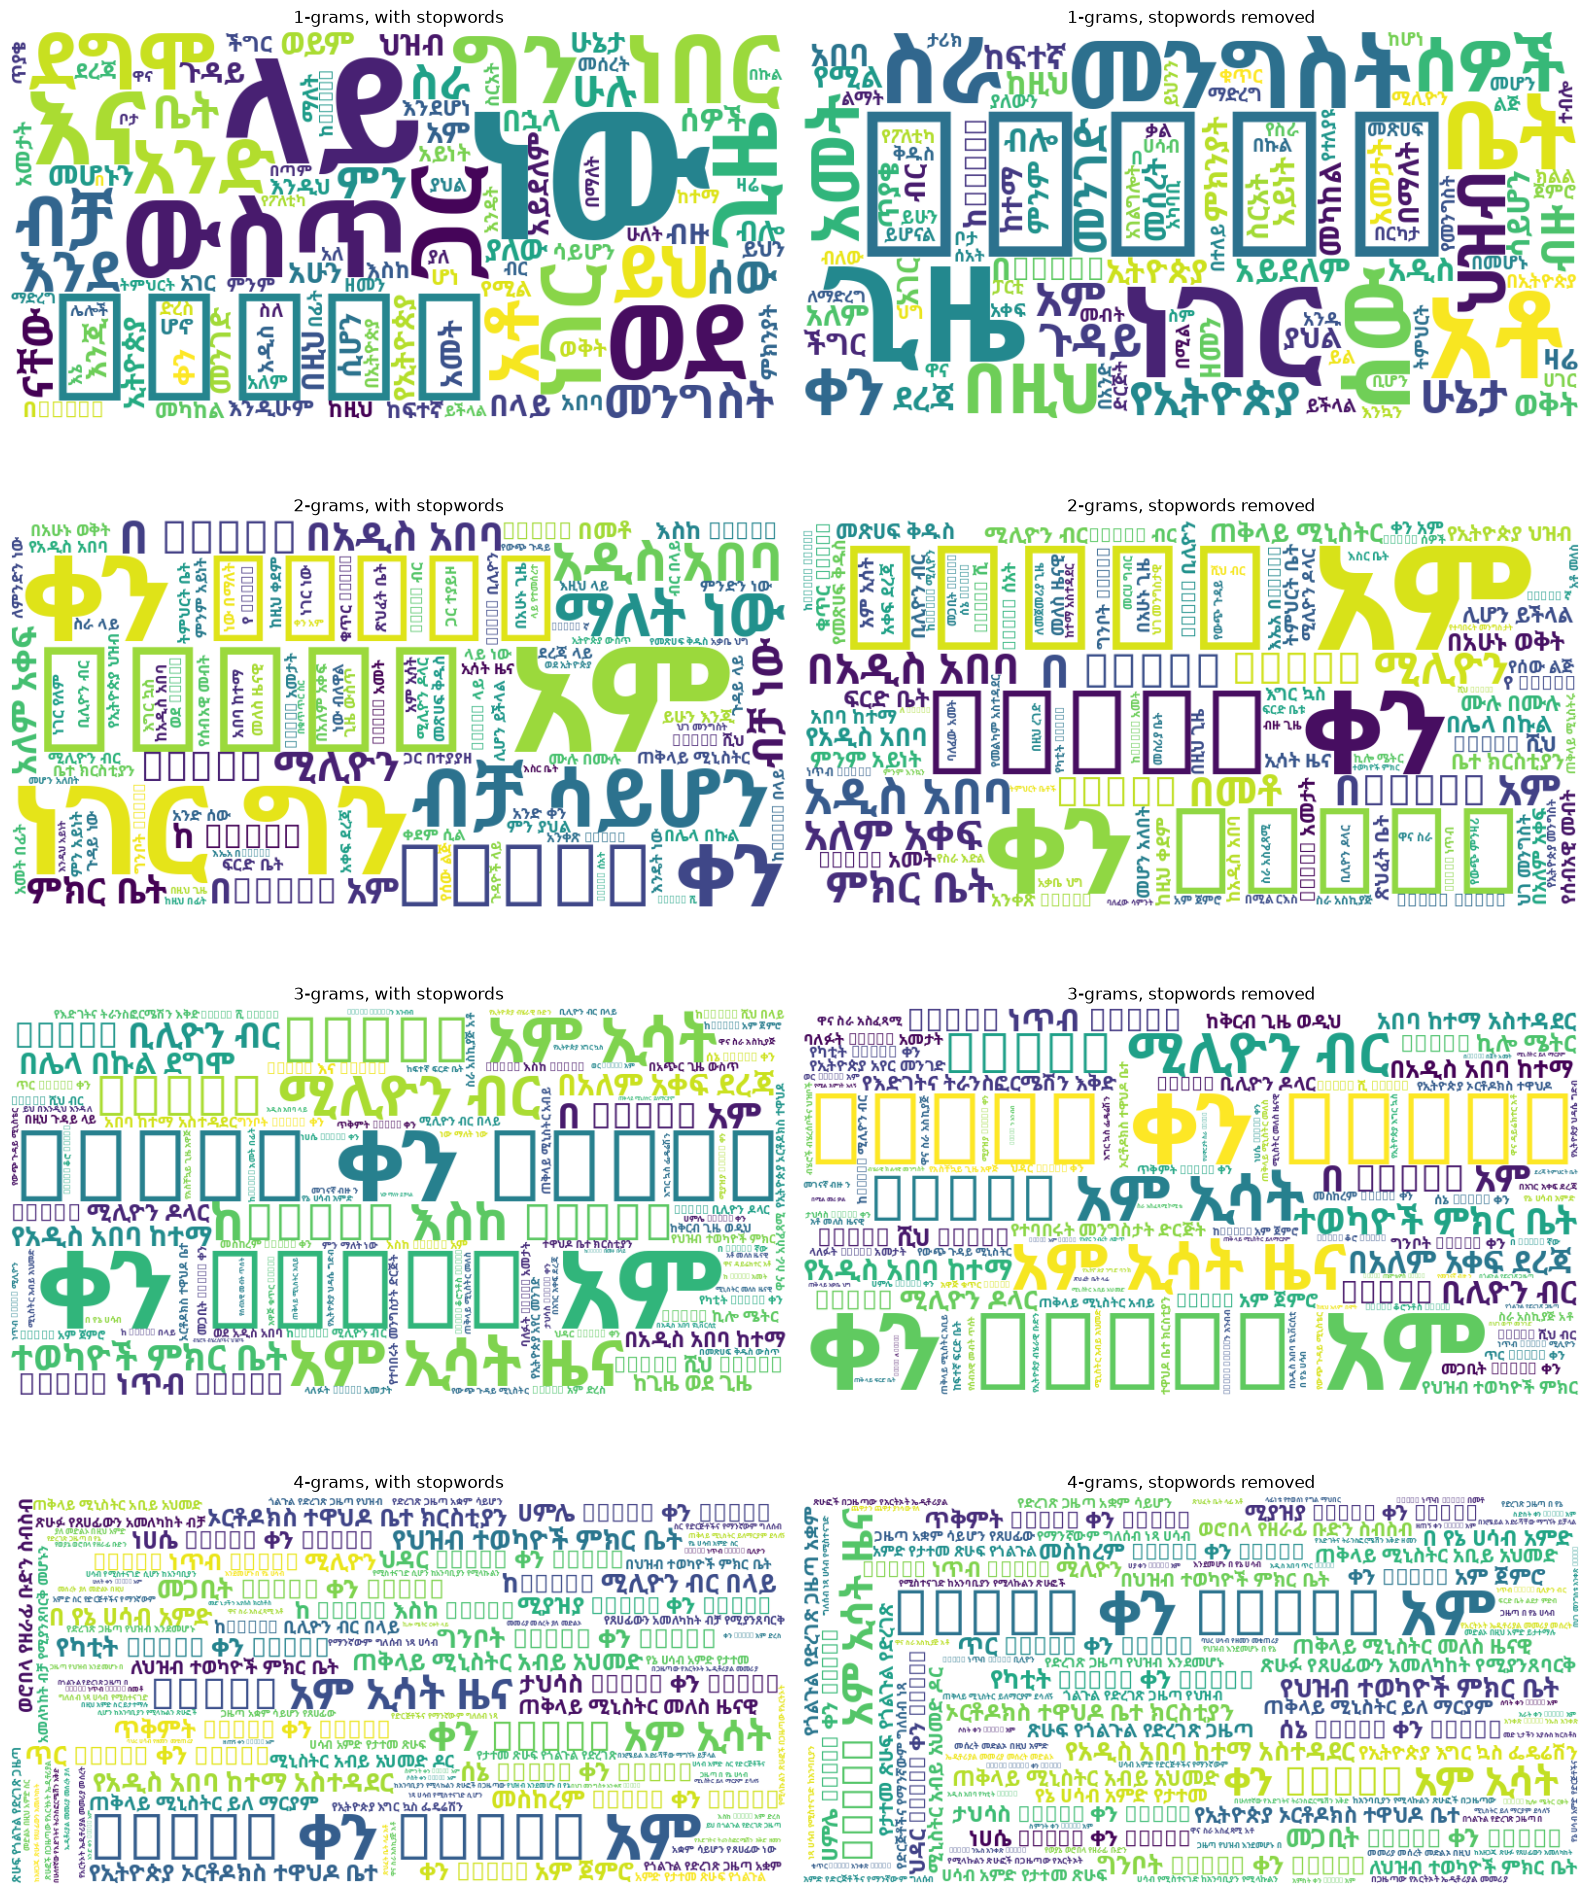

In [12]:
from ngram.viz import ngram_wordcloud, ethiopic_font
font = ethiopic_font(DATA)

def freqs(cnts, k, n=150):
    rows = cnts.top(k, n, exclude=MARKERS)
    return {" ".join(vocab.decode(g)): int(c)
            for g, c in zip(cnts.decode(k, rows), cnts.counts[k - 1][rows])}

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for k in range(1, 5):
    ngram_wordcloud(freqs(counts, k), axes[k - 1, 0], f"{k}-grams, with stopwords", font_path=font)
    ngram_wordcloud(freqs(counts_ns, k), axes[k - 1, 1], f"{k}-grams, stopwords removed", font_path=font)
plt.tight_layout(); plt.savefig(f"{FIGURES}/wordclouds.png", dpi=120)
del counts_ns   # free ~0.5 GB before the smoothed models below

## 1.7 Probability of a sentence

By the chain rule with the n-gram (Markov) approximation, a sentence w1 … wm has probability
P(w1 … wm) = Π_i P(w_i | w_{i−n+1} … w_{i−1}), including the final factor P(</s> | …) for the
sentence ending (the ። of the input). At sentence start the history is only `<s>`.

Three estimators are compared:

| model | P(w | h), where h is the history of up to n−1 words |
|---|---|
| MLE | c(h w) / c(h •) — zero for any unseen n-gram |
| Laplace | (c(h w) + 1) / (c(h •) + V), V = vocabulary size |
| Kneser-Ney | discounted counts interpolated with lower-order continuation probabilities |

Because 3- and 4-grams seen once were pruned, MLE treats them as unseen (probability 0); Kneser-Ney
moves their probability mass to the lower orders, so its distribution still sums to 1.

Log probabilities are natural logs; a product of many small probabilities underflows, so sums of
logs are reported.

In [13]:
from ngram.models import make_model
from ngram.normalize import preprocess

SENTENCES = ["ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።",
             "አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።",
             "ትገኛለች ቀንድ በአፍሪካ ኢትዮጵያ።",          # same words, scrambled order
             "የቡና ምርት በዚህ አመት ጨምሯል።"]

rows = []
for s in SENTENCES:
    toks = preprocess(s)[0]
    for kind in ("mle", "laplace", "kn"):
        for n in range(1, 5):
            _, logp = make_model(counts, n, kind).sentence_report(vocab, toks)
            rows.append({"sentence": s, "model": kind, "n": n, "log P": logp, "P": np.exp(logp)})
table = pd.DataFrame(rows)
display(table.pivot_table(index=["sentence", "model"], columns="n", values="log P", sort=False))

n                                          1          2          3          4
sentence                  model                                              
ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።    mle     -38.659331       -inf       -inf       -inf
                          laplace -38.726557 -41.052011 -52.278191 -53.009696
                          kn      -38.659331 -26.656784 -25.149893 -25.937224
አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት። mle     -45.509087 -29.017440 -19.592420 -16.164172
                          laplace -45.604290 -46.570783 -59.793002 -66.180528
                          kn      -45.509087 -28.956478 -19.424900 -15.933076
ትገኛለች ቀንድ በአፍሪካ ኢትዮጵያ።    mle     -38.659331       -inf       -inf       -inf
                          laplace -38.726557 -61.437250 -69.732878 -69.732871
                          kn      -38.659331 -51.670852 -49.131228 -49.539319
የቡና ምርት በዚህ አመት ጨምሯል።     mle     -45.004972 -34.190537       -inf       -inf
                          laplace -45.085535 -55.017743 -74.188185 -76.669431
                          kn      -45.004972 -34.206470 -32.600927 -33.117608

In [14]:
toks = preprocess(SENTENCES[0])[0]
print("tokens:", toks, "| in vocabulary:", [w in vocab.index for w in toks])
per_token = {}
for kind in ("mle", "laplace", "kn"):
    per, logp = make_model(counts, 4, kind).sentence_report(vocab, toks)
    per_token[f"{kind} (4-gram)"] = [p for _, p in per]
pd.DataFrame(per_token, index=[w for w, _ in per])

tokens: ['ኢትዮጵያ', 'በአፍሪካ', 'ቀንድ', 'ትገኛለች'] | in vocabulary: [True, True, True, True]


,mle (4-gram),laplace (4-gram),kn (4-gram)
ኢትዮጵያ,0.003876,3.176485e-03,0.003898
በአፍሪካ,0.007042,1.227966e-04,0.008187
ቀንድ,0.192000,2.479025e-05,0.242585
ትገኛለች,0.000000,9.916828e-07,0.000001
</s>,0.000000,9.917329e-07,0.625036


## 1.8 Random sentence generation

Generation samples one word at a time from the MLE distribution P(w | h) = c(h w) / c(h •) given
the previous n−1 words, starting from `<s>` and stopping at `</s>`. For each output we also check
whether it is copied verbatim from the training text.

In [15]:
from ngram.generate import generate
rng = np.random.default_rng(42)
generated = {n: [generate(counts, vocab, n, max_len=25, rng=rng) for _ in range(5)] for n in range(1, 5)}
wanted = {s for ss in generated.values() for s in ss}
with open(f"{MODEL_DIR}/train.txt", encoding="utf-8") as f:     # stream: the file is ~1 GB
    copied = {l.strip() for l in f if l.strip() in wanted}
for n, ss in generated.items():
    print(f"===== {n}-gram")
    for s in ss:
        print(("[copied] " if s in copied else "         ") + s)

===== 1-gram
         ለአንድነት ዘመቻ ከእምነቱ እየተከናወኑ ላይ አንሸከምም ከንፈር በወንጌል አንድ ታሪካዊ እጅ እንድንቀር አንስተዋል ይኑረን ኩባንያዎች ይችላል እስራኤል ነው ፖርቲ ደርሰዋል ከጎኔ ወይ ወንዜ እንደማይወጣ ከጋምቤላ
         በ<num> ምርጥ
         ሰዎች እየመጡ ጊዳዳ እንችላለንም እቅድ አዋጅ ሳለ አበባ ይህ አዳራሽ ትምህርት የትኞቹ ዘመናዊ ለቡድን የሚያስከትለው ብዬ በደካማ ተገኝተን ምሳሌ ውጤት ይረዳናል መንግስት መካከል
         ለተነሳው ዝና በአለ ዛምቢያ እንዲሆኑ ሙስሊሞች መንግስት ነበር ይባላሉ ክለቦች አነጋገር የምንላቸው ደቂቃዎች ኢንተርናሽናል ውጤቱ ይቻላል
         ይሄን ብር ዛሬም መፍጠን ሌላ
===== 2-gram
         በዚህም መሰረት ሄዋን የሚገልጸውን ምስራች ተገዢዎች እንደሆኑ ሊያውቁት ይገባል
         በዚህ አማካይነት የሚመጣ ሰው ቅርብ ጊዜ ተገንብቶ ተጠናቋል
         እግዚአብሄር ይመስገን አለ
         ከዚህ ለቃችሁ እየወጣችሁ ተቃውሞ ተቀባይነት እንደማይኖረውና በጽኑ እንዲታገሉ ሲደረግ የነበረውን አበባ ለሚገነባው የኢንዱስትሪ ግንባታ ተግባራዊ የሚደረገው ጥረት በሚመጣ ወራሪ ይሎችን ለመቋቋም የተወሰደው መቼ ሞተ
         የታሪክ ትምህርት ማግኘት አይቻልም
===== 3-gram
         ኢትዮጵያ ለዘላለም ትኑር የሚለው ቁምነገር ነው
[copied] ግን እፎይታው ብዙም አይቆይም
         ዘላቂ መፍትሄ እንዲፈለግለት ብጹአን አባቶቻችንን እኛ ከትንኟም ክንፍ የምናንሰው ምእመናን ከመውቀስ ተቆጥበን ቆይተናል
         አሁን የእኔ ጥያቄ የገንዘብ አይደለም የፍትህ እንጂ
         አሁንም ግን አደጋው የከፋ እንደሚሆን አያጠራጥርም
===== 4-gram

**What happens as n increases**

- **Unigram:** each word is drawn independently by its frequency, so the output is a list of
  unrelated words (ለአንድነት ዘመቻ ከእምነቱ እየተከናወኑ ላይ …) with no grammar, and its length is random
  because `</s>` is just another frequent token.
- **Bigram:** every adjacent pair is plausible (በዚህ አማካይነት, ቅርብ ጊዜ), and short outputs can be
  whole sentences (እግዚአብሄር ይመስገን አለ). Longer ones drift from topic to topic, because the
  model only sees one previous word.
- **Trigram:** most outputs are grammatical sentences that end properly (ኢትዮጵያ ለዘላለም ትኑር
  የሚለው ቁምነገር ነው), and one of the five is copied verbatim from the training text.
- **4-gram:** sentences are fluent, but two of the five are copies of training sentences. Most
  3-word histories have only a few continuations, so the sampler is repeating stored text. One
  output runs to the 25-word limit, because a long history can chain through rare phrases
  without reaching `</s>`.

As n grows, fluency rises and novelty falls. The model memorizes training sentences instead of
generalizing from them. This is the data-sparsity problem that smoothing addresses in Task 2.